# Chlorophyll-a Distribution Check
The goal of this analysis is to check if `chlorophyl` (chl-a) has a normal distribution.
If not, we perform a log transformation on all time series. Since a 0 value will cause problems with log transformation, we add `0.000001` to zero values (chl-a + 0.000001).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import sys
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# Add project root to sys.path to import utils
project_root = Path().resolve().parents[0]
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths

plt.style.use(str(ProjectPaths.PROJECT_ROOT / 'project_style.mplstyle'))

## 1. Load Data
We load the merged dataset which contains the `chlorophyl` column.

In [2]:
print("Loading data...")
merged_df = pd.read_feather(ProjectPaths.MERGED_DATA_FILE)

# Drop missing chl-a values for the distribution analysis
chla_data = merged_df['chlorophyl'].dropna()
print(f"Total valid chl-a records: {len(chla_data)}")
print(f"Summary statistics of original chl-a:\\n{chla_data.describe()}")

Loading data...
Total valid chl-a records: 62738
Summary statistics of original chl-a:\ncount    62738.000000
mean         5.043008
std         11.469950
min          0.000000
25%          0.866013
50%          1.900000
75%          4.500000
max        519.000000
Name: chlorophyl, dtype: float64


## 2. Check Original Distribution
We visualize the original `chlorophyl` distribution using a histogram and a Q-Q plot.

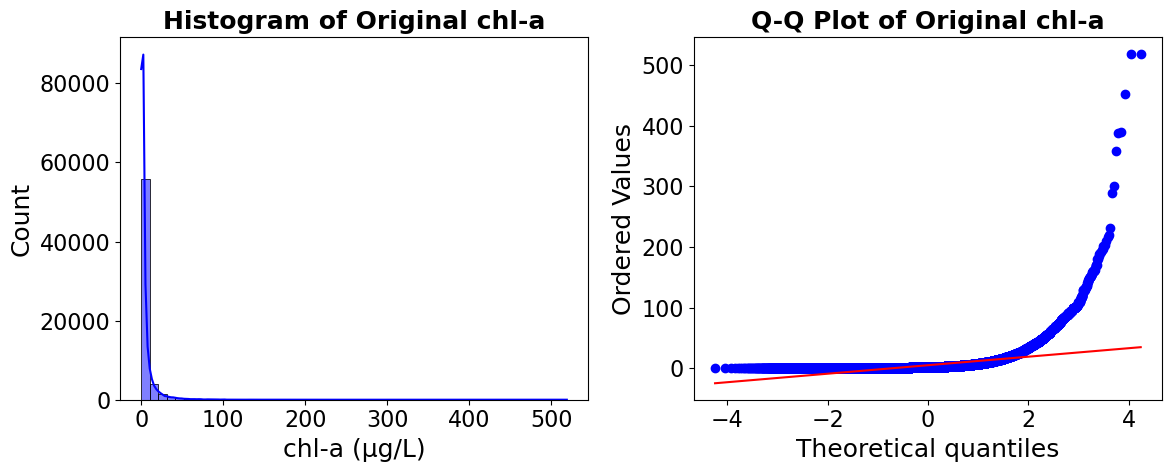

Shapiro-Wilk Test (Original) - Stat: 0.3294, p-value: 1.2599e-86
Probably NOT Gaussian (Normal) Distribution


In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Histogram
sns.histplot(chla_data, kde=True, ax=ax1, color='blue', bins=50)
ax1.set_title("Histogram of Original chl-a")
ax1.set_xlabel("chl-a (μg/L)")

# Q-Q Plot
stats.probplot(chla_data, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot of Original chl-a")

plt.tight_layout()
plt.show()

# Optional: Shapiro-Wilk Test (on a sample if N is very large)
sample_size = min(len(chla_data), 5000) # Shapiro-Wilk max N is 5000
stat, p = stats.shapiro(chla_data.sample(sample_size, random_state=42))
print(f"Shapiro-Wilk Test (Original) - Stat: {stat:.4f}, p-value: {p:.4e}")
if p > 0.05:
    print("Probably Gaussian (Normal) Distribution")
else:
    print("Probably NOT Gaussian (Normal) Distribution")

## 3. Log Transformation
The original distribution is likely right-skewed. We apply a log10 transformation.
Zero values are replaced with `0.000001` before taking the log.

In [4]:
# Replace 0 with 0.000001, otherwise keep the value
chla_transformed = chla_data.replace(0, 0.000001)

# Alternatively, the instruction was: "change it to very small value instead. (chl-a + 0.000001.)" 
# which could mean just add 0.000001 to 0 values, which replace does.
# Now apply log10
chla_log = np.log10(chla_transformed)

print(f"Summary statistics of log10(chl-a):\\n{chla_log.describe()}")

Summary statistics of log10(chl-a):\ncount    62738.000000
mean         0.068861
std          1.393088
min         -6.000000
25%         -0.062477
50%          0.278754
75%          0.653213
max          2.715167
Name: chlorophyl, dtype: float64


## 4. Check Log-Transformed Distribution
Visualize the log-transformed data.

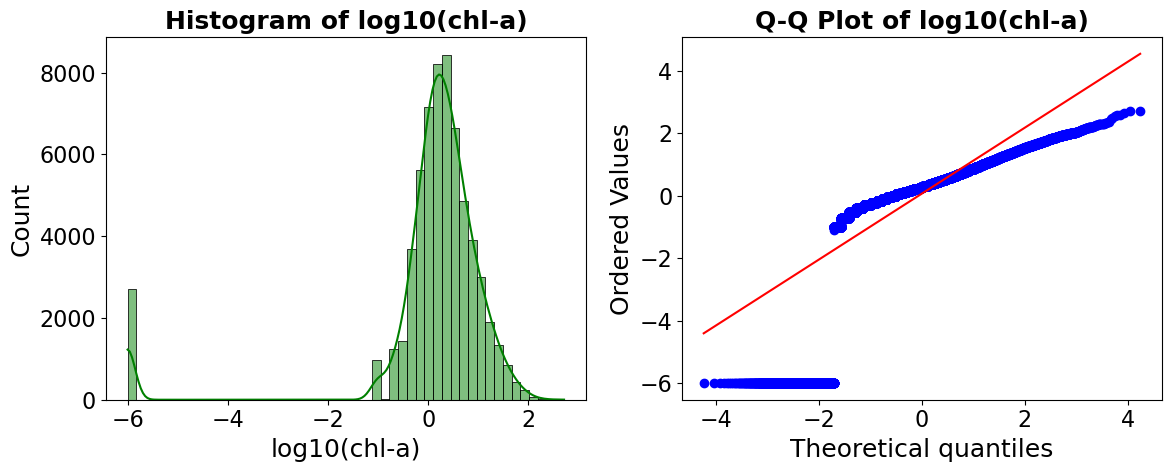

Shapiro-Wilk Test (Log Transformed) - Stat: 0.5758, p-value: 1.2371e-76
Probably NOT Gaussian (Normal) Distribution


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Histogram
sns.histplot(chla_log, kde=True, ax=ax1, color='green', bins=50)
ax1.set_title("Histogram of log10(chl-a)")
ax1.set_xlabel("log10(chl-a)")

# Q-Q Plot
stats.probplot(chla_log, dist="norm", plot=ax2)
ax2.set_title("Q-Q Plot of log10(chl-a)")

plt.tight_layout()
plt.show()

# Shapiro-Wilk Test
stat_log, p_log = stats.shapiro(chla_log.sample(sample_size, random_state=42))
print(f"Shapiro-Wilk Test (Log Transformed) - Stat: {stat_log:.4f}, p-value: {p_log:.4e}")
if p_log > 0.05:
    print("Probably Gaussian (Normal) Distribution")
else:
    print("Probably NOT Gaussian (Normal) Distribution")

## 5. Conclusion
We successfully tested the distribution of raw `chl-a` and applied a log transformation, handling zero values appropriately by using a small offset.